# Target transforms

**Airline passengers, retail sales and web traffic share a habit: the busier they get, the bigger their seasonal swing.** A model fitted to the raw numbers learns swings the size of those it has seen, which are smaller than the next one. So it falls short at the peaks and draws bands that are too narrow.

The usual fix is to model the logarithm, where a swing that grows in proportion to the level becomes a swing of fixed size, and to convert the forecast back at the end. That last step hides a trap: the average of the logs, converted back, is not the average forecast.

In this notebook we build series like that, fit the same simple model with and without logs, and score both on the original scale across 60 series. Then we look at the trap, and at how TimeGym avoids it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from timegym import Case, ForecastTask, GaussianAR1Forecaster, Pipeline, Scenario, SimulationReference
from timegym.diagnostics import evaluate_forecast
from timegym.statistics import paired_t_interval
from timegym.target import BoxCoxTransform, ComposedTransform, DifferenceTransform, LogTransform

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})
RAW, LOG = "Without logs", "With logs"
COLORS = {RAW: "#D55E00", LOG: "#0000CC"}

## A series whose swing grows with its level

TimeGym's `composite` scenario adds a straight line, a repeating cycle and noise. We read its values as logarithms and exponentiate them. The straight line becomes growth of about 1.2% a month, and the cycle becomes a seasonal swing that stays a fixed share of the level, so it grows as the level grows.

Because we generated the data, we also have the **answer key**: what a perfect forecaster that knows the true process would predict. The future logarithms follow a known bell curve, so the future values follow its exponential (a log-normal distribution), whose mean and spread we can compute exactly. The model only sees the history.

The table compares the first and the last year of one 10-year history.

In [2]:
HORIZON = 24
N_SAMPLES = 400
log_scenario = Scenario("composite", context_length=120, horizon=HORIZON, parameters={
    "intercept": np.log(100.), "slope": .012, "amplitude": .25, "period": 12., "sigma": .08})


def multiplicative_case(seed):
    # Exponentiate one composite case. The future logs are Gaussian, so the future
    # values are log-normal and the answer key stays exact.
    log_case = log_scenario.generate(seed=seed)
    log_reference = log_case.reference
    mean = np.exp(log_reference.mean + log_reference.variance / 2)
    covariance = np.outer(mean.ravel(), mean.ravel()) * np.expm1(log_reference.covariance)
    reference = SimulationReference(
        mean=mean, variance=np.diag(covariance).reshape(mean.shape), covariance=covariance,
        index=log_reference.index, target_names=log_reference.target_names,
        sampler=lambda n_samples, seed: np.exp(log_reference.sample(n_samples, seed)))
    return Case(task=ForecastTask(np.exp(log_case.task.context), log_case.task.future_index),
                observed=np.exp(log_case.observed), reference=reference,
                manifest={**log_case.manifest, "values": "exp(composite)"})


case = multiplicative_case(seed=3)
first_year = case.task.context.iloc[:12, 0]
last_year = case.task.context.iloc[-12:, 0]
display(pd.DataFrame({"average level": [first_year.mean(), last_year.mean()],
                      "seasonal swing": [np.ptp(first_year), np.ptp(last_year)]},
                     index=["first year of history", "last year of history"]).round(1))

,average level,seasonal swing
first year of history,113.7,57.8
last year of history,398.4,200.9


Over ten years the level grows about 3.5-fold, and the seasonal swing (highest month minus lowest) grows by the same factor.

## Fit the same model with and without logs

The model is deliberately simple: mean reversion (AR(1)), where shocks fade (`GaussianAR1Forecaster`). On its own it can't produce a seasonal cycle, so both pipelines first take a 12-month difference, each month minus the same month a year earlier (`DifferenceTransform(lag=12)`). The model then forecasts those yearly changes. One pipeline takes logs first (`LogTransform`), so its model forecasts yearly growth rates instead of yearly changes in units.

A pipeline's `target_transform` is fitted on each history, the model sees only the transformed values, and the forecast is converted back before it is returned, so you always get it in the original units. The transform is part of the pipeline's saved settings, so a saved report can rebuild it.

In [3]:
pipelines = {
    RAW: Pipeline(GaussianAR1Forecaster(n_samples=N_SAMPLES, seed=29),
                  target_transform=DifferenceTransform(lag=12)),
    LOG: Pipeline(GaussianAR1Forecaster(n_samples=N_SAMPLES, seed=29),
                  target_transform=ComposedTransform([LogTransform(), DifferenceTransform(lag=12)])),
}
forecasts = {name: pipeline.predict(case.task.context, case.task.future_index)
             for name, pipeline in pipelines.items()}

config = pipelines[LOG].to_config()
assert Pipeline.from_config(config).to_config() == config  # the saved settings rebuild the transform
steps = config["target_transform"]["parameters"]["transforms"]
print("Saved transform:", ", then ".join(
    f"{step['class']}({', '.join(f'{key}={value}' for key, value in step['parameters'].items())})"
    for step in steps))

Saved transform: LogTransform(), then DifferenceTransform(order=1, lag=12)


## Without logs, the forecast falls short at the peaks

Here are both forecasts, already converted back to the original units. Crosses are the forecast, gray dots are what actually happened, and the thin gray line is the answer key. The shaded band runs from each forecast's 10% to its 90% quantile: an 80% band for each step on its own, not a band the whole path stays inside 80% of the time.

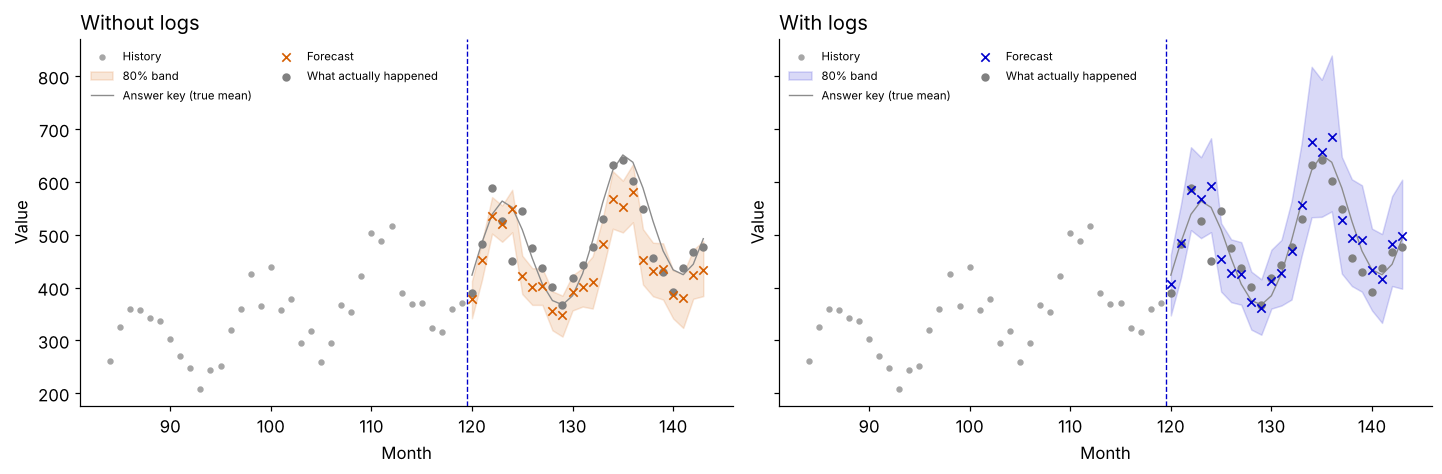

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True, sharey=True, constrained_layout=True)
history = case.task.context.iloc[-36:]
future = case.task.future_index
for ax, (name, forecast) in zip(axes, forecasts.items()):
    ax.scatter(history.index, history.iloc[:, 0], color="0.65", s=10, label="History")
    ax.fill_between(future, forecast.quantiles[:, 0, 0], forecast.quantiles[:, 0, -1],
                    color=COLORS[name], alpha=.15, label="80% band")
    ax.plot(future, case.reference.mean[:, 0], color="0.55", linewidth=.9, label="Answer key (true mean)")
    ax.scatter(future, forecast.point[:, 0], marker="x", color=COLORS[name], s=30, linewidths=1.1,
               label="Forecast", zorder=4)
    ax.scatter(future, case.observed.iloc[:, 0], color="0.5", s=20, label="What actually happened", zorder=3)
    ax.axvline(future[0] - .5, color="#0000CC", linestyle="--", linewidth=.9)
    ax.set(title=name, xlabel="Month", ylabel="Value")
    ax.legend(fontsize=7.5, loc="upper left", ncol=2)
plt.show()

Without logs, the model adds a yearly change in units, learned from the whole history, to last year's value. When growth is proportional, the true yearly change is larger at the peaks than in the troughs, and larger now than early in the history. So this forecast falls short, most of all at the peaks, and its band stays about the same width at peaks and troughs. With logs, the swing has a fixed size before the difference is taken, so the forecast follows the swing and its band widens with the level.

## Is one series luck? Score 60 of them

We generate 60 independent series, fit both pipelines to each history and score the converted forecasts. Four numbers per forecast:

- error against the answer key (`mean_reference_mse`): how far the forecast is from the true mean;
- error against what actually happened (`mse`), which also includes noise nobody can predict;
- CRPS (`crps`): a score for the whole forecast distribution, not just its center;
- coverage (`interval_coverage`): how often what actually happened fell inside the 80% band.

Lower is better for the first three. Coverage should be near 80%.

In [5]:
N_CASES = 60
records = []
for seed in range(1000, 1000 + N_CASES):
    series_case = multiplicative_case(seed)
    for name, pipeline in pipelines.items():
        result = evaluate_forecast(series_case, pipeline.predict(series_case.task.context,
                                                                 series_case.task.future_index))
        records.append({"seed": seed, "pipeline": name,
                        "error against the answer key": result.metrics["mean_reference_mse"],
                        "error against what happened": result.metrics["mse"],
                        "CRPS": result.metrics["crps"],
                        "80% band coverage": result.metrics["interval_coverage"]})
scores = pd.DataFrame(records)
display(scores.drop(columns="seed").groupby("pipeline", sort=False).mean().round(3))

,error against the answer key,error against what happened,CRPS,80% band coverage
pipeline,,,,
Without logs,3965.830,5951.055,46.886,0.456
With logs,1712.456,3432.948,32.674,0.859


Logs lower all three errors, and the error against the answer key falls by more than half. Without logs, the 80% bands catch what happened only 46% of the time; with logs, 86%.

An average can hide a few lucky series, so we compare the two pipelines series by series. Each series counts once: its 24 steps move together, so they are not 24 more comparisons.

,logs lower on,average difference,95% interval
error against the answer key,55 of 60 series,-2253.4,-2644.1 to -1862.6
error against what happened,56 of 60 series,-2518.1,-2973.5 to -2062.7
CRPS,57 of 60 series,-14.2,-16.3 to -12.1


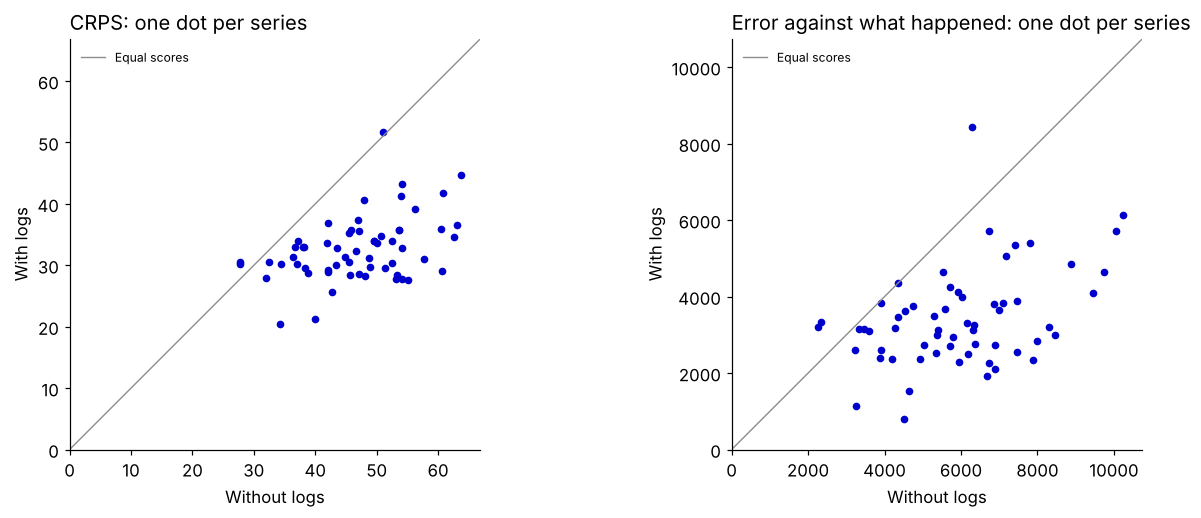

In [6]:
paired = {}
for metric in ("error against the answer key", "error against what happened", "CRPS"):
    table = scores.pivot(index="seed", columns="pipeline", values=metric)
    difference = table[LOG] - table[RAW]
    interval = paired_t_interval(difference)
    paired[metric] = {"logs lower on": f"{(difference < 0).sum()} of {len(difference)} series",
                      "average difference": round(interval["mean"], 1),
                      "95% interval": f"{interval['ci95'][0]:.1f} to {interval['ci95'][1]:.1f}"}
    assert interval["ci95"][1] < 0  # logs win on this score across series
display(pd.DataFrame(paired).T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
for ax, metric, title in zip(axes, ("CRPS", "error against what happened"),
                             ("CRPS", "Error against what happened")):
    table = scores.pivot(index="seed", columns="pipeline", values=metric)
    ax.scatter(table[RAW], table[LOG], s=16, color="#0000CC")
    limits = [0, table.max().max() * 1.05]
    ax.plot(limits, limits, color="0.55", linewidth=.9, label="Equal scores")
    ax.set(xlim=limits, ylim=limits, aspect="equal", title=f"{title}: one dot per series",
           xlabel=RAW, ylabel=LOG)
    ax.legend(fontsize=8, loc="upper left")
plt.show()

Dots below the diagonal are series where logs win. Logs win on 55 to 57 of the 60 series, depending on the score, and for every score the 95% interval for the average difference sits well below zero.

## The catch: exp of the average is not the average

In the pipeline with logs, the model forecasts the average future logarithm. The obvious way back is to exponentiate that average, and the answer always comes out too low. The exponential stretches high values more than it squeezes low ones, so the average of the exponentials is larger than the exponential of the average (Jensen's inequality). When the logs follow a bell curve, exponentiating their average gives the median of the values, and the mean is higher by a factor `exp(v/2)`, where `v` is the variance of the log. That factor depends on the spread, so no formula in the average log alone can recover the mean.

Quantiles and samples don't have this problem: the exponential of the 90% quantile of the log is the 90% quantile of the value. So TimeGym exponentiates the sample paths and takes the point forecast as their average. Without samples, it converts the median instead.

Below we rebuild the pipeline with logs by hand and compare the two ways back on the same 400 sample paths.

In [7]:
log_transform, seasonal_difference = LogTransform(), DifferenceTransform(lag=12)
logged = log_transform.fit_transform(case.task.context)
model = GaussianAR1Forecaster(n_samples=N_SAMPLES, seed=29).fit(seasonal_difference.fit_transform(logged))
log_levels = seasonal_difference.inverse_transform(model.predict(case.task.future_index))
restored = log_transform.inverse_transform(log_levels)
np.testing.assert_array_equal(restored.point, forecasts[LOG].point)  # by hand = the pipeline, exactly

log_paths = log_levels.samples[:, :, 0]
comparison = pd.DataFrame({
    "exp(average log)": np.exp(log_paths.mean(axis=0)),
    "average of exp(log): TimeGym's point": restored.point[:, 0],
    "ratio": restored.point[:, 0] / np.exp(log_paths.mean(axis=0)),
    "exp(v / 2)": np.exp(log_paths.var(axis=0) / 2),
}, index=pd.RangeIndex(1, HORIZON + 1, name="months ahead"))
assert (comparison["ratio"] > 1).all()  # exponentiating the average log always comes out low
display(comparison.iloc[[0, 11, 23]].round(4))

,exp(average log),average of exp(log): TimeGym's point,ratio,exp(v / 2)
months ahead,,,,
1,403.3316,405.8473,1.0062,1.0062
12,425.5784,428.3698,1.0066,1.0065
24,491.4192,497.7607,1.0129,1.0128


At every step the average of the exponentials is higher, and the ratio matches `exp(v/2)`. The gap grows with the horizon, from 0.6% one month ahead to 1.3% two years ahead, because uncertainty about the log builds up. It is small here only because the noise is small. It is a bias, not sampling noise: more samples would not remove it.

## You don't have to guess the logarithm

Here we knew the series was built from logarithms. On a real series you would not. `BoxCoxTransform` estimates a power from each history alone: a power of 1 leaves the shape unchanged, and a power of 0 is the logarithm.

In [8]:
box_cox = BoxCoxTransform()
box_cox.fit_transform(case.task.context)
print(f"Box-Cox power estimated from this history: {box_cox.lambdas_[0]:.3f}")

Box-Cox power estimated from this history: -0.021


It picks -0.021, very close to zero: the data ask for the logarithm. Box-Cox converts back with the same rule as `LogTransform`, so the catch above is handled the same way.

## Change one thing

- Replace `LogTransform()` with `BoxCoxTransform()` in the pipeline with logs and compare the scores.
- Raise `sigma` to 0.2 and watch the ratio in the catch table grow.
- Drop the seasonal difference and fit the AR(1) to logs alone: the model loses the season.
- Set `slope` and `amplitude` to zero, so that nothing grows with the level, and see whether logs still help.

**What this doesn't show.** These results come from one generator and one simple model, so they don't say which transform suits a real series. Coverage pools the 24 steps of each series, which move together, so it is a rough reading, not a calibration test.

Reading: [Box and Cox (1964)](https://doi.org/10.1111/j.2517-6161.1964.tb00553.x).

**Next:** [Reductions](05_reductions.ipynb).